# LAB 09 — Named Entity Recognition and Information Extraction
**Dataset:** CoNLL-2003 | **Backbone:** bert-base-cased

Mục tiêu: BIO tagging, subword label alignment, baseline Logistic Regression, fine-tuning Transformer token classification, entity-level evaluation và Information Extraction. Khuyến nghị chạy trên Google Colab GPU.

## 0. Cài đặt và import

In [1]:
# Colab nếu thiếu thư viện:
!pip -q install datasets transformers accelerate seqeval scikit-learn seaborn

import os, time, json, random
from collections import Counter, defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModelForTokenClassification, DataCollatorForTokenClassification, Trainer, TrainingArguments
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from seqeval.metrics import precision_score, recall_score, f1_score, classification_report
from seqeval.scheme import IOB2

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
OUT="lab09_outputs"; os.makedirs(OUT,exist_ok=True)
MODEL_NAME="bert-base-cased"; MAX_LENGTH=128
print("Device:",DEVICE)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Device: cuda


## 1. CoNLL-2003 dataset và BIO labels

In [2]:

from datasets import load_dataset

# Load CoNLL-2003 từ repository có namespace đầy đủ
base_url = (
    "https://huggingface.co/datasets/lhoestq/conll2003/"
    "resolve/main/data/"
)

data_files = {
    "train": base_url + "train-00000-of-00001.parquet",
    "validation": base_url + "validation-00000-of-00001.parquet",
    "test": base_url + "test-00000-of-00001.parquet"
}

ds = load_dataset("parquet", data_files=data_files)

# Chuyển nhãn ID sang BIO labels

# Danh sách nhãn chuẩn CoNLL-2003
label_names = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC"
]

id2label = {i: label for i, label in enumerate(label_names)}
label2id = {label: i for i, label in id2label.items()}

def rows(split):
    return [
        {
            "tokens": row["tokens"],
            "tags": [id2label[int(t)] for t in row["ner_tags"]]
        }
        for row in ds[split]
    ]

train_data = rows("train")
valid_data = rows("validation")
test_data = rows("test")

print("Labels:", label_names)
print("Train:", len(train_data))
print("Validation:", len(valid_data))
print("Test:", len(test_data))

print("\nSample:", train_data[0])

# Kiểm tra dữ liệu
for data in [train_data, valid_data, test_data]:
    assert all(len(r["tokens"]) == len(r["tags"]) for r in data)

print("\nDataset loaded successfully!")


data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
Train: 14041
Validation: 3250
Test: 3453

Sample: {'tokens': ['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.'], 'tags': ['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']}

Dataset loaded successfully!


## 2. Tokenization và label alignment — Strategy A

In [3]:
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME)

def align_one(words, tags):
    enc=tokenizer(words,is_split_into_words=True,truncation=True,max_length=MAX_LENGTH)
    word_ids=enc.word_ids()
    aligned=[]; previous=None
    for wid in word_ids:
        if wid is None or wid==previous: aligned.append(-100)
        else: aligned.append(label2id[tags[wid]])
        previous=wid
    return enc,aligned

# Quan sát một câu cụ thể
sample=train_data[0]
enc,aligned=align_one(sample["tokens"],sample["tags"])
display(pd.DataFrame({
    "subword":tokenizer.convert_ids_to_tokens(enc["input_ids"]),
    "word_id":enc.word_ids(),
    "aligned_label":[id2label[x] if x!=-100 else "IGNORE" for x in aligned]
}))

# Thống kê tối thiểu 20 câu; lưu CSV
stats=[]
for i,r in enumerate(test_data[:200]):
    e=tokenizer(r["tokens"],is_split_into_words=True,truncation=True,max_length=MAX_LENGTH)
    wids=[x for x in e.word_ids() if x is not None]
    counts=Counter(wids)
    stats.append({"sentence_id":i,"words":len(r["tokens"]),"subword_tokens":len(wids),
                  "subword_splits":sum(v>1 for v in counts.values()),
                  "R_subwords_per_word":len(wids)/max(1,len(r["tokens"])),
                  "entity_words":sum(t!="O" for t in r["tags"])})
token_stats=pd.DataFrame(stats)
token_stats.to_csv(f"{OUT}/tokenization_stats.csv",index=False)
display(token_stats.head())

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

,subword,word_id,aligned_label
0,[CLS],NaN,IGNORE
1,EU,0.0,B-ORG
2,rejects,1.0,O
3,German,2.0,B-MISC
4,call,3.0,O
5,to,4.0,O
6,boycott,5.0,O
7,British,6.0,B-MISC
8,la,7.0,O
9,##mb,7.0,IGNORE


,sentence_id,words,subword_tokens,subword_splits,R_subwords_per_word,entity_words
0,0,12,31,8,2.583333,2
1,1,2,6,2,3.000000,2
2,2,6,13,2,2.166667,4
3,3,25,27,1,1.080000,4
4,4,25,28,2,1.120000,2


## 3. Baseline — token features + Logistic Regression

In [4]:
def feats(words,i):
    w=words[i]
    return {"lower":w.lower(),"title":w.istitle(),"upper":w.isupper(),"digit":w.isdigit(),
            "pre2":w[:2].lower(),"pre3":w[:3].lower(),"suf2":w[-2:].lower(),"suf3":w[-3:].lower(),
            "prev":words[i-1].lower() if i else "<BOS>",
            "next":words[i+1].lower() if i<len(words)-1 else "<EOS>"}

def flatten(data):
    X=[]; y=[]; lengths=[]
    for r in data:
        lengths.append(len(r["tokens"]))
        for i,t in enumerate(r["tags"]): X.append(feats(r["tokens"],i)); y.append(t)
    return X,y,lengths

Xtr,ytr,_=flatten(train_data); Xte,yte,test_lengths=flatten(test_data)
vec=DictVectorizer(); Xtr=vec.fit_transform(Xtr); Xte=vec.transform(Xte)
baseline=LogisticRegression(max_iter=300,class_weight="balanced")
t0=time.time(); baseline.fit(Xtr,ytr); baseline_time=time.time()-t0
flat_pred=baseline.predict(Xte)
def regroup(flat,lengths):
    out=[]; pos=0
    for n in lengths: out.append(list(flat[pos:pos+n])); pos+=n
    return out
base_pred=regroup(flat_pred,test_lengths)
gold=[r["tags"] for r in test_data]
base_p=precision_score(gold,base_pred,scheme=IOB2,zero_division=0)
base_r=recall_score(gold,base_pred,scheme=IOB2,zero_division=0)
base_f= f1_score(gold,base_pred,scheme=IOB2,zero_division=0)
print(classification_report(gold,base_pred,scheme=IOB2,zero_division=0))

              precision    recall  f1-score   support

         LOC       0.74      0.82      0.78      1668
        MISC       0.53      0.73      0.61       702
         ORG       0.48      0.67      0.56      1661
         PER       0.63      0.79      0.70      1617

   micro avg       0.60      0.76      0.67      5648
   macro avg       0.60      0.75      0.66      5648
weighted avg       0.61      0.76      0.67      5648



## 4. Pretrained Transformer token classification

In [5]:
def to_hf(data):
    return Dataset.from_dict({"tokens":[r["tokens"] for r in data],
        "ner_tags":[[label2id[t] for t in r["tags"]] for r in data]})

def preprocess(batch):
    tok=tokenizer(batch["tokens"],is_split_into_words=True,truncation=True,max_length=MAX_LENGTH)
    all_labels=[]
    for i,word_labels in enumerate(batch["ner_tags"]):
        word_ids=tok.word_ids(batch_index=i); prev=None; labels=[]
        for wid in word_ids:
            if wid is None or wid==prev: labels.append(-100)
            else: labels.append(word_labels[wid])
            prev=wid
        all_labels.append(labels)
    tok["labels"]=all_labels
    return tok

train_tok=to_hf(train_data).map(preprocess,batched=True)
valid_tok=to_hf(valid_data).map(preprocess,batched=True)
test_tok=to_hf(test_data).map(preprocess,batched=True)
model=AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,num_labels=len(label_names),id2label=id2label,label2id=label2id)

def metrics(eval_pred):
    logits,labels=eval_pred; pred=np.argmax(logits,axis=2)
    pp=[]; yy=[]
    for a,b in zip(pred,labels):
        p=[]; y=[]
        for pi,yi in zip(a,b):
            if yi!=-100: p.append(id2label[int(pi)]); y.append(id2label[int(yi)])
        pp.append(p); yy.append(y)
    return {"precision":precision_score(yy,pp,scheme=IOB2,zero_division=0),
            "recall":recall_score(yy,pp,scheme=IOB2,zero_division=0),
            "f1":f1_score(yy,pp,scheme=IOB2,zero_division=0)}

args=TrainingArguments(output_dir=f"{OUT}/checkpoint",learning_rate=2e-5,
    per_device_train_batch_size=16,per_device_eval_batch_size=32,num_train_epochs=3,
    weight_decay=0.01,eval_strategy="epoch",save_strategy="epoch",
    load_best_model_at_end=True,metric_for_best_model="f1",report_to="none",
    seed=SEED,fp16=torch.cuda.is_available())
trainer=Trainer(model=model,args=args,train_dataset=train_tok,eval_dataset=valid_tok,
    processing_class=tokenizer,data_collator=DataCollatorForTokenClassification(tokenizer),
    compute_metrics=metrics)
t0=time.time(); trainer.train(); transformer_time=time.time()-t0

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

## 5. Đánh giá entity-level và lưu results.csv

In [6]:
pred_out=trainer.predict(test_tok)
pred_ids=np.argmax(pred_out.predictions,axis=2)
trans_pred=[]; trans_gold=[]
for pp,yy in zip(pred_ids,pred_out.label_ids):
    p=[]; y=[]
    for a,b in zip(pp,yy):
        if b!=-100: p.append(id2label[int(a)]); y.append(id2label[int(b)])
    trans_pred.append(p); trans_gold.append(y)

tp=precision_score(trans_gold,trans_pred,scheme=IOB2,zero_division=0)
tr=recall_score(trans_gold,trans_pred,scheme=IOB2,zero_division=0)
tf=f1_score(trans_gold,trans_pred,scheme=IOB2,zero_division=0)
results=pd.DataFrame([
 {"model":"Logistic Regression baseline","precision":base_p,"recall":base_r,"f1":base_f,"train_seconds":baseline_time},
 {"model":MODEL_NAME+" fine-tuned","precision":tp,"recall":tr,"f1":tf,"train_seconds":transformer_time}
])
results.to_csv(f"{OUT}/results.csv",index=False)
display(results)
print(classification_report(trans_gold,trans_pred,scheme=IOB2,zero_division=0))

,model,precision,recall,f1,train_seconds
0,Logistic Regression baseline,0.596570,0.757436,0.667447,65.887098
1,bert-base-cased fine-tuned,0.903619,0.920269,0.911868,260.144652


              precision    recall  f1-score   support

         LOC       0.93      0.93      0.93      1666
        MISC       0.78      0.82      0.80       702
         ORG       0.87      0.91      0.89      1661
         PER       0.96      0.95      0.96      1615

   micro avg       0.90      0.92      0.91      5644
   macro avg       0.89      0.91      0.90      5644
weighted avg       0.91      0.92      0.91      5644



## 6. Entity type metrics và confusion_matrix.png

,entity,precision,recall,f1
0,PER,0.964956,0.954799,0.959851
1,ORG,0.873921,0.913907,0.893467
2,LOC,0.932894,0.934574,0.933733
3,MISC,0.775538,0.821937,0.798064


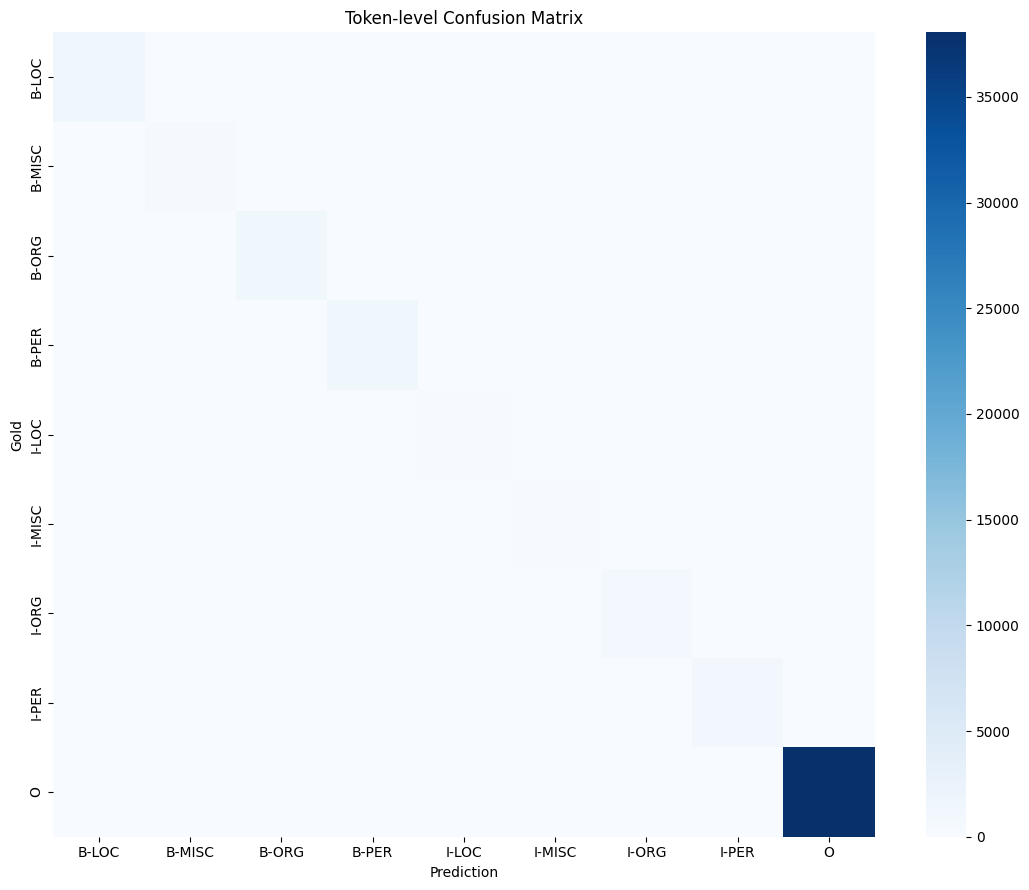

In [7]:
entity_rows=[]
for typ in ["PER","ORG","LOC","MISC"]:
    gy=[[t if t.endswith("-"+typ) else "O" for t in s] for s in trans_gold]
    py=[[t if t.endswith("-"+typ) else "O" for t in s] for s in trans_pred]
    entity_rows.append({"entity":typ,"precision":precision_score(gy,py,scheme=IOB2,zero_division=0),
        "recall":recall_score(gy,py,scheme=IOB2,zero_division=0),
        "f1":f1_score(gy,py,scheme=IOB2,zero_division=0)})
entity_metrics=pd.DataFrame(entity_rows)
entity_metrics.to_csv(f"{OUT}/entity_metrics.csv",index=False)
display(entity_metrics)

flat_gold=[x for s in trans_gold for x in s]; flat_pred=[x for s in trans_pred for x in s]
labs=sorted(set(flat_gold)|set(flat_pred))
cm=confusion_matrix(flat_gold,flat_pred,labels=labs)
plt.figure(figsize=(11,9)); sns.heatmap(cm,xticklabels=labs,yticklabels=labs,cmap="Blues")
plt.xlabel("Prediction"); plt.ylabel("Gold"); plt.title("Token-level Confusion Matrix")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png",dpi=180); plt.show()

## 7. Entity length analysis — entity_length_analysis.png

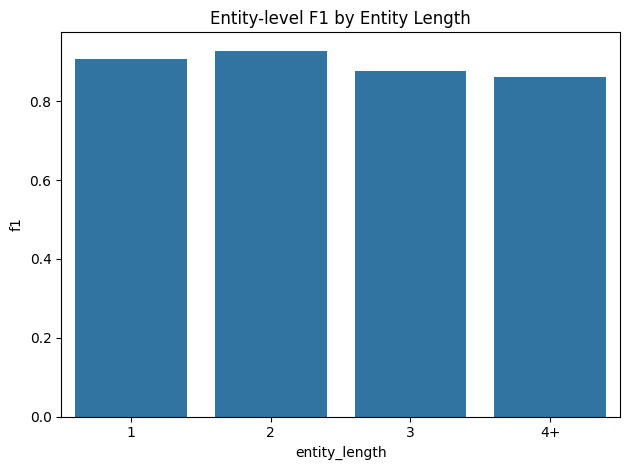

,entity_length,TP,FP,FN,precision,recall,f1
0,1,3279,378,294,0.896637,0.917716,0.907054
1,2,1653,136,120,0.923980,0.932318,0.928130
2,3,206,28,30,0.880342,0.872881,0.876596
3,4+,56,12,6,0.823529,0.903226,0.861538


In [8]:
def get_entities(words,tags):
    out=[]; start=None; typ=None
    for i,tag in enumerate(tags+["O"]):
        if tag=="O" or tag.startswith("B-"):
            if start is not None: out.append((start,i,typ," ".join(words[start:i])))
            start=None; typ=None
            if tag.startswith("B-"): start=i; typ=tag[2:]
        elif tag.startswith("I-") and (start is None or typ!=tag[2:]):
            if start is not None: out.append((start,i,typ," ".join(words[start:i])))
            start=i; typ=tag[2:]
    return out

counts=defaultdict(lambda:Counter())
for row,g,pred in zip(test_data,trans_gold,trans_pred):
    ge=get_entities(row["tokens"],g); pe=get_entities(row["tokens"],pred)
    gs={(a,b,t) for a,b,t,_ in ge}; ps={(a,b,t) for a,b,t,_ in pe}
    for a,b,t,_ in ge:
        bucket=str(b-a) if b-a<4 else "4+"
        counts[bucket]["tp" if (a,b,t) in ps else "fn"]+=1
    for a,b,t,_ in pe:
        if (a,b,t) not in gs:
            bucket=str(b-a) if b-a<4 else "4+"
            counts[bucket]["fp"]+=1
length_rows=[]
for bucket in ["1","2","3","4+"]:
    c=counts[bucket]; p=c["tp"]/(c["tp"]+c["fp"]) if c["tp"]+c["fp"] else 0
    r=c["tp"]/(c["tp"]+c["fn"]) if c["tp"]+c["fn"] else 0
    f=2*p*r/(p+r) if p+r else 0
    length_rows.append({"entity_length":bucket,"TP":c["tp"],"FP":c["fp"],"FN":c["fn"],"precision":p,"recall":r,"f1":f})
length_df=pd.DataFrame(length_rows); length_df.to_csv(f"{OUT}/entity_length_metrics.csv",index=False)
sns.barplot(data=length_df,x="entity_length",y="f1")
plt.title("Entity-level F1 by Entity Length"); plt.tight_layout()
plt.savefig(f"{OUT}/entity_length_analysis.png",dpi=180); plt.show()
display(length_df)

## 8. Error analysis — xuất ví dụ FP, FN, boundary

In [9]:
error_rows=[]
for sid,(row,g,pred) in enumerate(zip(test_data,trans_gold,trans_pred)):
    ge=get_entities(row["tokens"],g); pe=get_entities(row["tokens"],pred)
    gs={(a,b,t) for a,b,t,_ in ge}; ps={(a,b,t) for a,b,t,_ in pe}
    for e in pe:
        a,b,t,txt=e
        if (a,b,t) not in gs:
            overlap=any(max(a,x)<min(b,y) for x,y,_,_ in ge)
            error_rows.append({"sentence_id":sid,"text":" ".join(row["tokens"]),
                "gold":[z[3]+"/"+z[2] for z in ge],"prediction":[z[3]+"/"+z[2] for z in pe],
                "error_type":"boundary_error" if overlap else "false_positive","entity":txt,"type":t})
    for e in ge:
        a,b,t,txt=e
        if (a,b,t) not in ps:
            overlap=any(max(a,x)<min(b,y) for x,y,_,_ in pe)
            error_rows.append({"sentence_id":sid,"text":" ".join(row["tokens"]),
                "gold":[z[3]+"/"+z[2] for z in ge],"prediction":[z[3]+"/"+z[2] for z in pe],
                "error_type":"boundary_error" if overlap else "false_negative","entity":txt,"type":t})
errors=pd.DataFrame(error_rows)
selected=pd.concat([errors[errors.error_type==k].head(5) for k in ["false_positive","false_negative","boundary_error"]])
selected.to_csv(f"{OUT}/error_analysis.csv",index=False)
display(selected)
print("Available errors:",errors.error_type.value_counts().to_dict())

,sentence_id,text,gold,prediction,error_type,entity,type
1,0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","[JAPAN/LOC, CHINA/PER]","[JAPAN/PER, LUCKY/LOC, CHINA/PER]",false_positive,LUCKY,LOC
3,3,Japan began the defence of their Asian Cup tit...,"[Japan/LOC, Asian Cup/MISC, Syria/LOC]","[Japan/LOC, Asian Cup/MISC, Syria/LOC, Group C...",false_positive,Group C,MISC
62,298,CRICKET - LARA SUFFERS MORE AUSTRALIAN TOUR MI...,[LARA/PER],"[LARA/ORG, AUSTRALIAN/MISC, MISERY/MISC]",false_positive,AUSTRALIAN,MISC
63,298,CRICKET - LARA SUFFERS MORE AUSTRALIAN TOUR MI...,[LARA/PER],"[LARA/ORG, AUSTRALIAN/MISC, MISERY/MISC]",false_positive,MISERY,MISC
87,358,EASTERN CONFERENCE,[],[EASTERN/MISC],false_positive,EASTERN,MISC
10,22,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...,"[RUGBY UNION/ORG, CUTTITTA/PER, ITALY/LOC]","[RUGBY UNION/ORG, CUTTITTA/ORG]",false_negative,ITALY,LOC
35,189,RUGBY UNION - LITTLE TO MISS CAMPESE FAREWELL .,"[RUGBY UNION/ORG, LITTLE/PER, CAMPESE/PER]","[RUGBY UNION/ORG, LITTLE/LOC]",false_negative,CAMPESE,PER
47,248,CRICKET - AUSTRALIA V WEST INDIES WORLD SERIES...,"[AUSTRALIA/LOC, WEST INDIES/LOC, WORLD SERIES/...",[AUSTRALIA/LOC],false_negative,WEST INDIES,LOC
48,248,CRICKET - AUSTRALIA V WEST INDIES WORLD SERIES...,"[AUSTRALIA/LOC, WEST INDIES/LOC, WORLD SERIES/...",[AUSTRALIA/LOC],false_negative,WORLD SERIES,MISC
49,287,CRICKET - AUSTRALIA BEAT WEST INDIES BY FIVE W...,"[AUSTRALIA/LOC, WEST INDIES/LOC]",[AUSTRALIA/LOC],false_negative,WEST INDIES,LOC


Available errors: {'boundary_error': 779, 'false_positive': 159, 'false_negative': 66}


## 9. Information Extraction — ví dụ News

In [10]:
def extract_information(text):
    words=text.split()
    inputs=tokenizer(words,is_split_into_words=True,return_tensors="pt",truncation=True,max_length=MAX_LENGTH)
    inputs={k:v.to(DEVICE) for k,v in inputs.items()}
    model.eval()
    with torch.no_grad(): ids=model(**inputs).logits.argmax(-1)[0].cpu().tolist()
    wids=tokenizer(words,is_split_into_words=True,truncation=True,max_length=MAX_LENGTH).word_ids()
    tags={}
    for wid,pid in zip(wids,ids):
        if wid is not None and wid not in tags: tags[wid]=id2label[pid]
    ents=get_entities(words,[tags.get(i,"O") for i in range(len(words))])
    result={"PERSON":[],"ORG":[],"LOCATION":[],"MISC":[]}
    for _,_,typ,txt in ents:
        result[{"PER":"PERSON","ORG":"ORG","LOC":"LOCATION","MISC":"MISC"}[typ]].append(txt)
    return result

news="Microsoft CEO Satya Nadella visited Paris on Tuesday."
print(json.dumps({"text":news,"entities":extract_information(news)},ensure_ascii=False,indent=2))
# TODO: tạo gold annotations cho ít nhất 30 câu và tính entity-level P/R/F1.

{
  "text": "Microsoft CEO Satya Nadella visited Paris on Tuesday.",
  "entities": {
    "PERSON": [
      "Satya Nadella"
    ],
    "ORG": [
      "Microsoft"
    ],
    "LOCATION": [
      "Paris"
    ],
    "MISC": []
  }
}


## 10. Lưu model, thông tin tái lập và deliverables

In [11]:
trainer.save_model(f"{OUT}/bert_ner"); tokenizer.save_pretrained(f"{OUT}/bert_ner")
repro={"model":MODEL_NAME,"tokenizer":MODEL_NAME,"dataset":"CoNLL-2003",
 "train_split":len(train_data),"validation_split":len(valid_data),"test_split":len(test_data),
 "max_sequence_length":MAX_LENGTH,"batch_size":16,"learning_rate":2e-5,"epochs":3,
 "optimizer":"AdamW","random_seed":SEED,"hardware":DEVICE,
 "alignment":"first subword label; continuation/special tokens=-100"}
with open(f"{OUT}/reproducibility.json","w") as f: json.dump(repro,f,indent=2)
print("Files:",os.listdir(OUT))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Files: ['tokenization_stats.csv', 'results.csv', 'entity_length_analysis.png', 'confusion_matrix.png', 'entity_metrics.csv', 'bert_ner', 'error_analysis.csv', 'checkpoint', 'entity_length_metrics.csv', 'reproducibility.json']



## 11. Xuất các file deliverables còn lại

Cell này tạo `baseline_ner.py`, `information_extraction.py`, `README.md`, `calculations.md`, `error_analysis.md` và `reflection.md`. Phần nhận xét kết quả trong error analysis/reflection cần được bạn bổ sung sau khi chạy notebook.


In [12]:

baseline_code = r"""# Baseline NER: token features + Logistic Regression
from datasets import load_dataset
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from seqeval.metrics import classification_report, f1_score
from seqeval.scheme import IOB2
import time

def features(words, i):
    w=words[i]
    return {"lower":w.lower(),"title":w.istitle(),"upper":w.isupper(),
            "prefix3":w[:3].lower(),"suffix3":w[-3:].lower(),
            "prev":words[i-1].lower() if i else "<BOS>",
            "next":words[i+1].lower() if i<len(words)-1 else "<EOS>"}

def main():
    ds=load_dataset("conll2003")
    names=ds["train"].features["ner_tags"].feature.names
    train,test=[],[]
    for split,target in [("train",train),("test",test)]:
        for row in ds[split]:
            target.append((row["tokens"],[names[int(x)] for x in row["ner_tags"]]))
    X=[]; y=[]
    for words,tags in train:
        for i,t in enumerate(tags): X.append(features(words,i)); y.append(t)
    vec=DictVectorizer(); X=vec.fit_transform(X)
    Xt=[]; yt=[]; lens=[]
    for words,tags in test:
        lens.append(len(words))
        for i,t in enumerate(tags): Xt.append(features(words,i)); yt.append(t)
    Xt=vec.transform(Xt)
    model=LogisticRegression(max_iter=300,class_weight="balanced")
    start=time.time(); model.fit(X,y); elapsed=time.time()-start
    pred=model.predict(Xt); pred_seq=[]; pos=0
    for n in lens: pred_seq.append(list(pred[pos:pos+n])); pos+=n
    gold=[x[1] for x in test]
    print(classification_report(gold,pred_seq,scheme=IOB2,zero_division=0))
    print("Entity F1:",f1_score(gold,pred_seq,scheme=IOB2,zero_division=0))
    print("Training seconds:",elapsed)

if __name__=="__main__": main()
"""
with open("baseline_ner.py","w",encoding="utf-8") as f: f.write(baseline_code)

ie_code = r"""# Information Extraction using the fine-tuned LAB09 token classifier
import torch
from transformers import AutoTokenizer, AutoModelForTokenClassification

MODEL_DIR="lab09_outputs/bert_ner"

def load_ner():
    return (AutoTokenizer.from_pretrained(MODEL_DIR),
            AutoModelForTokenClassification.from_pretrained(MODEL_DIR))

def bio_to_entities(words,tags):
    result=[]; start=None; kind=None
    for i,tag in enumerate(tags+["O"]):
        if tag=="O" or tag.startswith("B-"):
            if start is not None:
                result.append({"text":" ".join(words[start:i]),"type":kind})
            start=None; kind=None
            if tag.startswith("B-"): start=i; kind=tag[2:]
        elif tag.startswith("I-") and (start is None or kind!=tag[2:]):
            if start is not None:
                result.append({"text":" ".join(words[start:i]),"type":kind})
            start=i; kind=tag[2:]
    return result

def extract(text,tokenizer,model):
    words=text.split()
    enc=tokenizer(words,is_split_into_words=True,return_tensors="pt",truncation=True)
    model.eval()
    with torch.no_grad(): ids=model(**enc).logits.argmax(-1)[0].tolist()
    word_ids=tokenizer(words,is_split_into_words=True,truncation=True).word_ids()
    tags={}
    for wid,pid in zip(word_ids,ids):
        if wid is not None and wid not in tags:
            tags[wid]=model.config.id2label[pid]
    entities=bio_to_entities(words,[tags.get(i,"O") for i in range(len(words))])
    output={"PERSON":[],"ORG":[],"LOCATION":[],"MISC":[]}
    for e in entities:
        output[{"PER":"PERSON","ORG":"ORG","LOC":"LOCATION","MISC":"MISC"}[e["type"]]].append(e["text"])
    return output

if __name__=="__main__":
    tok,model=load_ner()
    print(extract("Barack Obama visited Paris.",tok,model))
"""
with open("information_extraction.py","w",encoding="utf-8") as f: f.write(ie_code)

readme = """# LAB 09 — Named Entity Recognition and Information Extraction

- Dataset: CoNLL-2003.
- Baseline: token-level lexical/context features + Logistic Regression.
- Transformer: bert-base-cased fine-tuned for token classification.
- Alignment: first subword gets the word BIO label; special and continuation subwords use -100.
- Run `tokenizer_alignment.ipynb`, then `ner_finetuning.ipynb` from top to bottom.
- Recommended runtime: Google Colab GPU.
- The notebook exports CSV and PNG evaluation artifacts to `lab09_outputs/`.
"""
open("README.md","w",encoding="utf-8").write(readme)
calc = """# Calculations — LAB 09

- BIO: B-X marks the beginning of entity X; I-X marks its continuation; O means outside an entity.
- Hidden states: H has shape (B, T, d); token logits Z has shape (B, T, C); labels Y has shape (B, T).
- For B=8, T=128, d=768, C=9: H=(8,128,768), Z=(8,128,9), Y=(8,128).
- Subword ratio R = number of subword tokens / number of original words.
- Entity precision = TP/(TP+FP); recall = TP/(TP+FN); F1 = 2PR/(P+R). Count TP/FP/FN by exact entity span and type.
- Alignment strategy: label first subword; ignore continuation subwords and special tokens with -100.
"""
open("calculations.md","w",encoding="utf-8").write(calc)
open("error_analysis.md","w",encoding="utf-8").write("# Error Analysis — LAB 09\n\nSau khi chạy notebook, bổ sung tối thiểu 5 false positives, 5 false negatives và 5 boundary errors từ `lab09_outputs/error_analysis.csv`. Giải thích dựa trên ngữ cảnh, loại entity và ranh giới entity; không suy diễn khi chưa có ví dụ.\n")
open("reflection.md","w",encoding="utf-8").write("# Reflection — LAB 09\n\nTODO: Tự viết reflection dựa trên kết quả chạy thật; đề cập BIO, subword alignment, entity-level metrics, contextual representation và giới hạn/domain shift.\n")
print("Đã thêm cell xuất file và tạo các file tài liệu/script.")


Đã thêm cell xuất file và tạo các file tài liệu/script.
